
# **Projet de Prédiction du Prix des Voitures**




- ÉTAPE 1 :  Importation et Exploration Initiale des Données



In [17]:

# 1. Importation des librairies nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings("ignore")


# Configuration d'affichage
%matplotlib inline
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)

print("Librairies importées avec succès !\n")

Librairies importées avec succès !



In [18]:
# 2. Chargement du dataset
df = pd.read_csv("car_price_prediction.csv")

print("Dataset chargé avec succès !")
print(f"→ Nombre de lignes (observations)    : {df.shape[0]:,}")
print(f"→ Nombre de colonnes (variables)     : {df.shape[1]}")

Dataset chargé avec succès !
→ Nombre de lignes (observations)    : 19,237
→ Nombre de colonnes (variables)     : 18


In [19]:
# 3. Aperçu des 5 premières lignes
print("\nAPERÇU DES 5 PREMIÈRES LIGNES :\n")
display(df.head())


APERÇU DES 5 PREMIÈRES LIGNES :



,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [20]:
# 4. Structure du dataset : types de données et informations générales
print("\nINFORMATIONS SUR LA STRUCTURE DU DATASET :\n")
df.info()


INFORMATIONS SUR LA STRUCTURE DU DATASET :

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  object 
 3   Manufacturer      19237 non-null  object 
 4   Model             19237 non-null  object 
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  object 
 7   Leather interior  19237 non-null  object 
 8   Fuel type         19237 non-null  object 
 9   Engine volume     19237 non-null  object 
 10  Mileage           19237 non-null  object 
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  object 
 13  Drive wheels      19237 non-null  object 
 14  Doors             19237 non-null  object 
 15  Wheel             19237 non-null  object 


In [21]:
# 5. Analyse statistique descriptive (uniquement variables numériques)
print("\nSTATISTIQUES DESCRIPTIVES (variables numériques) :\n")
display(df.describe().T)


STATISTIQUES DESCRIPTIVES (variables numériques) :



,count,mean,std,min,25%,50%,75%,max
ID,19237.0,4.557654e+07,936591.422799,20746880.0,45698374.0,45772308.0,45802036.0,45816654.0
Price,19237.0,1.855593e+04,190581.269684,1.0,5331.0,13172.0,22075.0,26307500.0
Prod. year,19237.0,2.010913e+03,5.668673,1939.0,2009.0,2012.0,2015.0,2020.0
Cylinders,19237.0,4.582991e+00,1.199933,1.0,4.0,4.0,4.0,16.0
Airbags,19237.0,6.582627e+00,4.320168,0.0,4.0,6.0,12.0,16.0


In [22]:
# 6. Analyse descriptive des variables catégorielles
print("\nSTATISTIQUES DESCRIPTIVES (variables catégorielles) :\n")
display(df.describe(include='object').T)


STATISTIQUES DESCRIPTIVES (variables catégorielles) :



,count,unique,top,freq
Levy,19237,559,-,5819
Manufacturer,19237,65,HYUNDAI,3769
Model,19237,1590,Prius,1083
Category,19237,11,Sedan,8736
Leather interior,19237,2,Yes,13954
Fuel type,19237,7,Petrol,10150
Engine volume,19237,107,2,3916
Mileage,19237,7687,0 km,721
Gear box type,19237,4,Automatic,13514
Drive wheels,19237,3,Front,12874


In [23]:
# 7. Vérification des valeurs manquantes
print("\nVALEURS MANQUANTES PAR COLONNE :\n")
missing_values = df.isnull().sum()
missing_percent = (missing_values / len(df)) * 100
missing_table = pd.DataFrame({
    'Valeurs manquantes': missing_values,
    'Pourcentage (%)': missing_percent.round(2)
})
missing_table = missing_table[missing_table['Valeurs manquantes'] > 0]
if missing_table.empty:
    print("Aucune valeur manquante détectée dans le dataset !")
else:
    display(missing_table.sort_values('Valeurs manquantes', ascending=False))


VALEURS MANQUANTES PAR COLONNE :

Aucune valeur manquante détectée dans le dataset !


In [24]:
# 8. Vérification des doublons
print("\nDOUBLONS :\n")
duplicates = df.duplicated().sum()
print(f"Nombre de lignes dupliquées : {duplicates}")

if duplicates > 0:
    print(f"→ {duplicates} lignes dupliquées détectées.")
    print("Exemple de doublons :")
    display(df[df.duplicated()].head())
else:
    print("Aucun doublon détecté.")


DOUBLONS :

Nombre de lignes dupliquées : 313
→ 313 lignes dupliquées détectées.
Exemple de doublons :


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
425,45815372,7840,-,MERCEDES-BENZ,E 200,1998,Sedan,No,CNG,2,180003 km,4.0,Manual,Rear,04-May,Left wheel,Black,4
1581,45815363,8781,-,TOYOTA,Ist,2002,Hatchback,No,Petrol,1.5,117000 km,4.0,Automatic,4x4,04-May,Right-hand drive,Red,4
1697,45732125,18503,-,TOYOTA,Prius,2010,Sedan,No,Petrol,1.8,162000 km,4.0,Automatic,Front,04-May,Left wheel,Grey,12
1972,45507765,20385,-,MERCEDES-BENZ,CLS 500,2005,Sedan,Yes,Petrol,5,230000 km,8.0,Tiptronic,Rear,04-May,Left wheel,Silver,10
2131,45815363,8781,-,TOYOTA,Ist,2002,Hatchback,No,Petrol,1.5,117000 km,4.0,Automatic,4x4,04-May,Right-hand drive,Red,4


In [25]:
# 9. Identification de la variable cible

target = "Price"
print(f"\nVARIABLE CIBLE IDENTIFIÉE : '{target}'")
print(f"Type : {df[target].dtype}")
print(f"Valeur minimale : {df[target].min():,}")
print(f"Valeur maximale : {df[target].max():,}")
print(f"Moyenne         : {df[target].mean():,.2f}")
print(f"Médiane         : {df[target].median():,.2f}")


VARIABLE CIBLE IDENTIFIÉE : 'Price'
Type : int64
Valeur minimale : 1
Valeur maximale : 26,307,500
Moyenne         : 18,555.93
Médiane         : 13,172.00


In [26]:
# 10. Identification des variables catégorielles vs numériques
print("\nCLASSIFICATION DES VARIABLES :\n")

# Variables numériques
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if target in numerical_cols:
    numerical_cols.remove(target)

print(f"Variables NUMÉRIQUES ({len(numerical_cols)}) :")
print(numerical_cols)

# Variables catégorielles
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"\nVariables CATÉGORIELLES ({len(categorical_cols)}) :")
print(categorical_cols)




CLASSIFICATION DES VARIABLES :

Variables NUMÉRIQUES (4) :
['ID', 'Prod. year', 'Cylinders', 'Airbags']

Variables CATÉGORIELLES (13) :
['Levy', 'Manufacturer', 'Model', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color']


- ÉTAPE 2 : Nettoyage et Prétraitement des Données

In [27]:

import pandas as pd
import numpy as np

1
df_clean = df.copy()
print(f"Taille initiale : {df_clean.shape[0]} lignes × {df_clean.shape[1]} colonnes\n")

# 1. Suppression des doublons
df_clean = df_clean.drop_duplicates()
print(f"1. Doublons supprimés → {df_clean.shape[0]} lignes restantes\n")

# 2. Nettoyage des colonnes
print("2. Nettoyage et conversion des colonnes")

# Levy : '-' → NaN → médiane
df_clean['Levy'] = df_clean['Levy'].replace('-', np.nan).astype(float)
df_clean['Levy'].fillna(df_clean['Levy'].median(), inplace=True)

# Engine volume + création Turbo
df_clean['Turbo'] = df_clean['Engine volume'].str.contains('Turbo', case=False, na=False).astype(int)
df_clean['Engine volume'] = df_clean['Engine volume'].str.replace(' Turbo', '', case=False).astype(float)

# Mileage : supprimer " km" et convertir en int
df_clean['Mileage'] = df_clean['Mileage'].str.replace(' km', '', regex=False).astype(int)

# Doors
df_clean['Doors'] = df_clean['Doors'].replace({'02-Mar': 2, '04-May': 4, '>5': 5})

# Leather interior → 0/1
df_clean['Leather interior'] = df_clean['Leather interior'].map({'Yes': 1, 'No': 0})

print("   Toutes les colonnes converties en numérique avec succès !\n")

# 3. Feature Engineering
print("3. Feature Engineering")

# Âge de la voiture
df_clean['Age'] = 2025 - df_clean['Prod. year']

# Suppression des colonnes inutiles
df_clean.drop(['Prod. year', 'ID'], axis=1, inplace=True)

# Log transformation de la cible
df_clean['log_price'] = np.log1p(df_clean['Price'])

print("   Age, Turbo, log_price créés → Prod. year et ID supprimés\n")

# 4. Traitement des outliers
print("4. Traitement des outliers")

# Price : suppression des 0.5% extrêmes
p005 = df_clean['Price'].quantile(0.005)
p995 = df_clean['Price'].quantile(0.995)
n_removed = ((df_clean['Price'] < p005) | (df_clean['Price'] > p995)).sum()

df_clean = df_clean[(df_clean['Price'] >= p005) & (df_clean['Price'] <= p995)]
print(f"   → {n_removed} lignes supprimées (outliers Price)")

# Mileage : capping au 99.5e percentile
mileage_cap = df_clean['Mileage'].quantile(0.995)
df_clean['Mileage'] = df_clean['Mileage'].clip(upper=mileage_cap)
print(f"   → Mileage cappé à {mileage_cap:,.0f} km\n")

# 5. One-Hot Encoding
print("5. One-Hot Encoding des variables catégorielles")
nominal_cols = ['Manufacturer', 'Model', 'Category', 'Fuel type',
                'Gear box type', 'Drive wheels', 'Wheel', 'Color']

df_clean = pd.get_dummies(df_clean, columns=nominal_cols, drop_first=True, dtype=int)
print(f"   → Après One-Hot : {df_clean.shape[1]} colonnes\n")

# 6. Séparation features / cible
print("6. Séparation features et cible")
y_price = df_clean['Price'].copy()        # pour évaluation finale en $
y       = df_clean['log_price'].copy()     # cible pour modélisation
X       = df_clean.drop(['Price', 'log_price'], axis=1)

print(f"X (features)  : {X.shape[0]} lignes × {X.shape[1]} colonnes")
print(f"y (log_price) : {y.shape[0]} valeurs")
print(f"y_price       : conservé pour interprétation business\n")


Taille initiale : 19237 lignes × 18 colonnes

1. Doublons supprimés → 18924 lignes restantes

2. Nettoyage et conversion des colonnes
   Toutes les colonnes converties en numérique avec succès !

3. Feature Engineering
   Age, Turbo, log_price créés → Prod. year et ID supprimés

4. Traitement des outliers
   → 142 lignes supprimées (outliers Price)
   → Mileage cappé à 761,689 km

5. One-Hot Encoding des variables catégorielles
   → Après One-Hot : 1672 colonnes

6. Séparation features et cible
X (features)  : 18782 lignes × 1670 colonnes
y (log_price) : 18782 valeurs
y_price       : conservé pour interprétation business



-  ÉTAPE 3 : ANALYSE EXPLORATOIRE DES DONNÉES (EDA) –

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

# On reconstruit un df lisible pour l'EDA à partir de X + les cibles
df_eda = X.copy()
df_eda['Price'] = y_price
df_eda['log_price'] = y

# On récupère quelques colonnes catégorielles originales depuis le df brut (df) pour les boxplots
df_original = df.copy()
# On garde seulement les lignes qui sont encore dans df_eda (après nettoyage)
df_original = df_original.loc[df_eda.index]

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("="*90)
print("ÉTAPE 3 : ANALYSE EXPLORATOIRE DES DONNÉES (EDA) – VERSION FINALE")
print("="*90)


MemoryError: Unable to allocate 239. MiB for an array with shape (1666, 18782) and data type int64


1. Analyse univariée



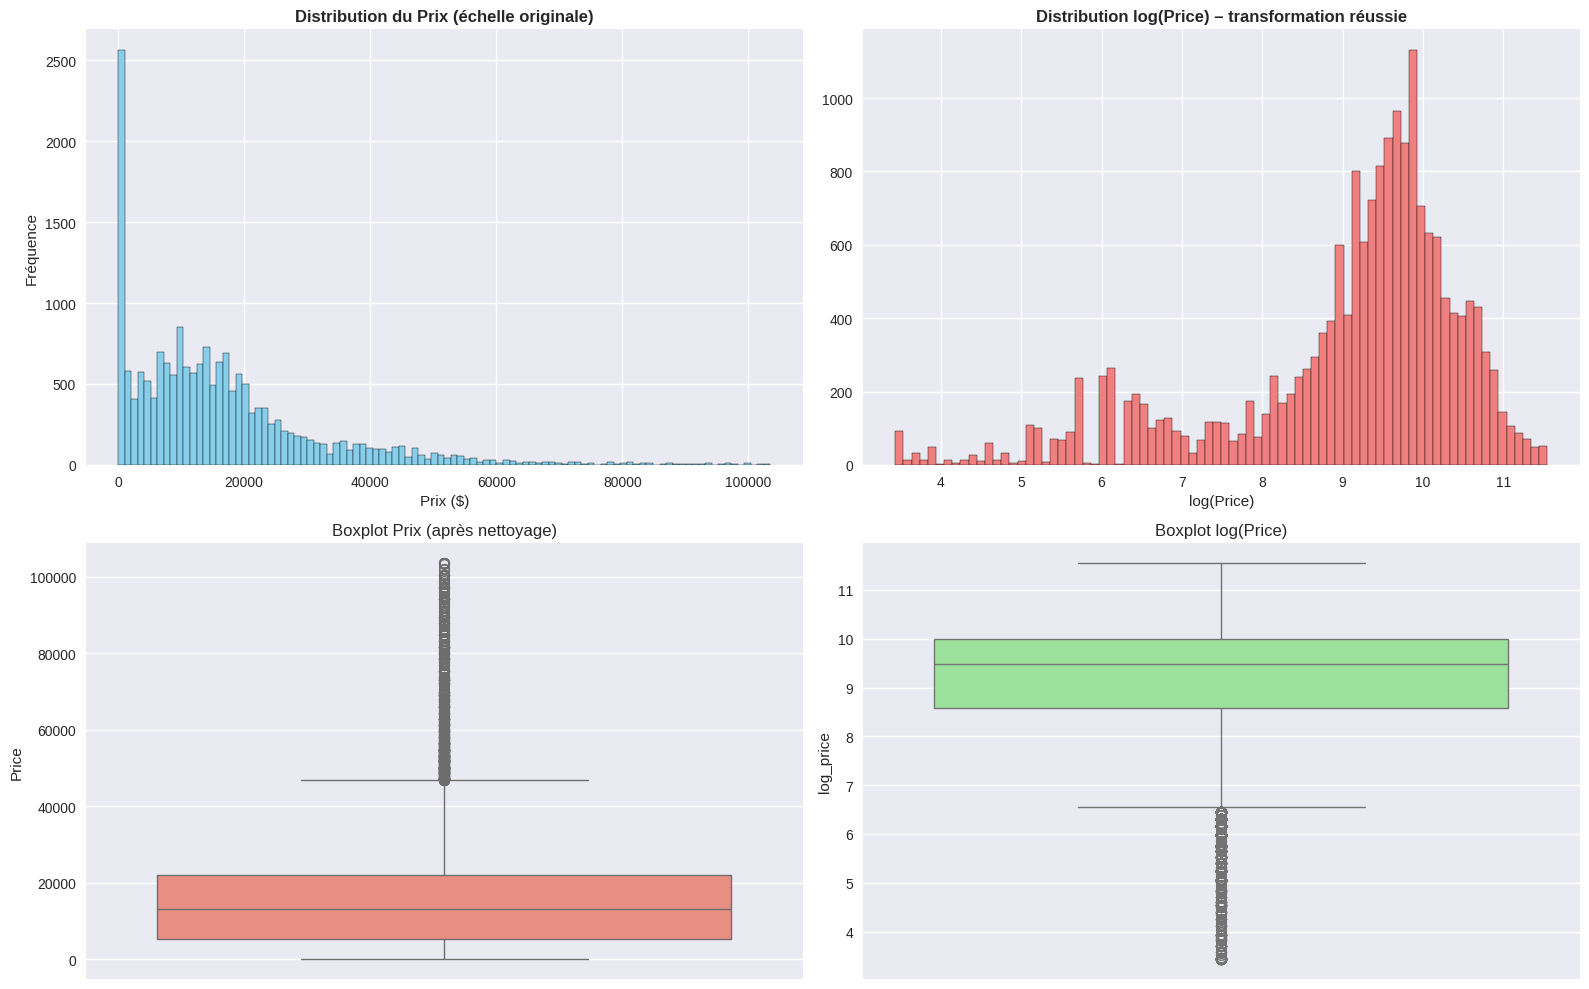

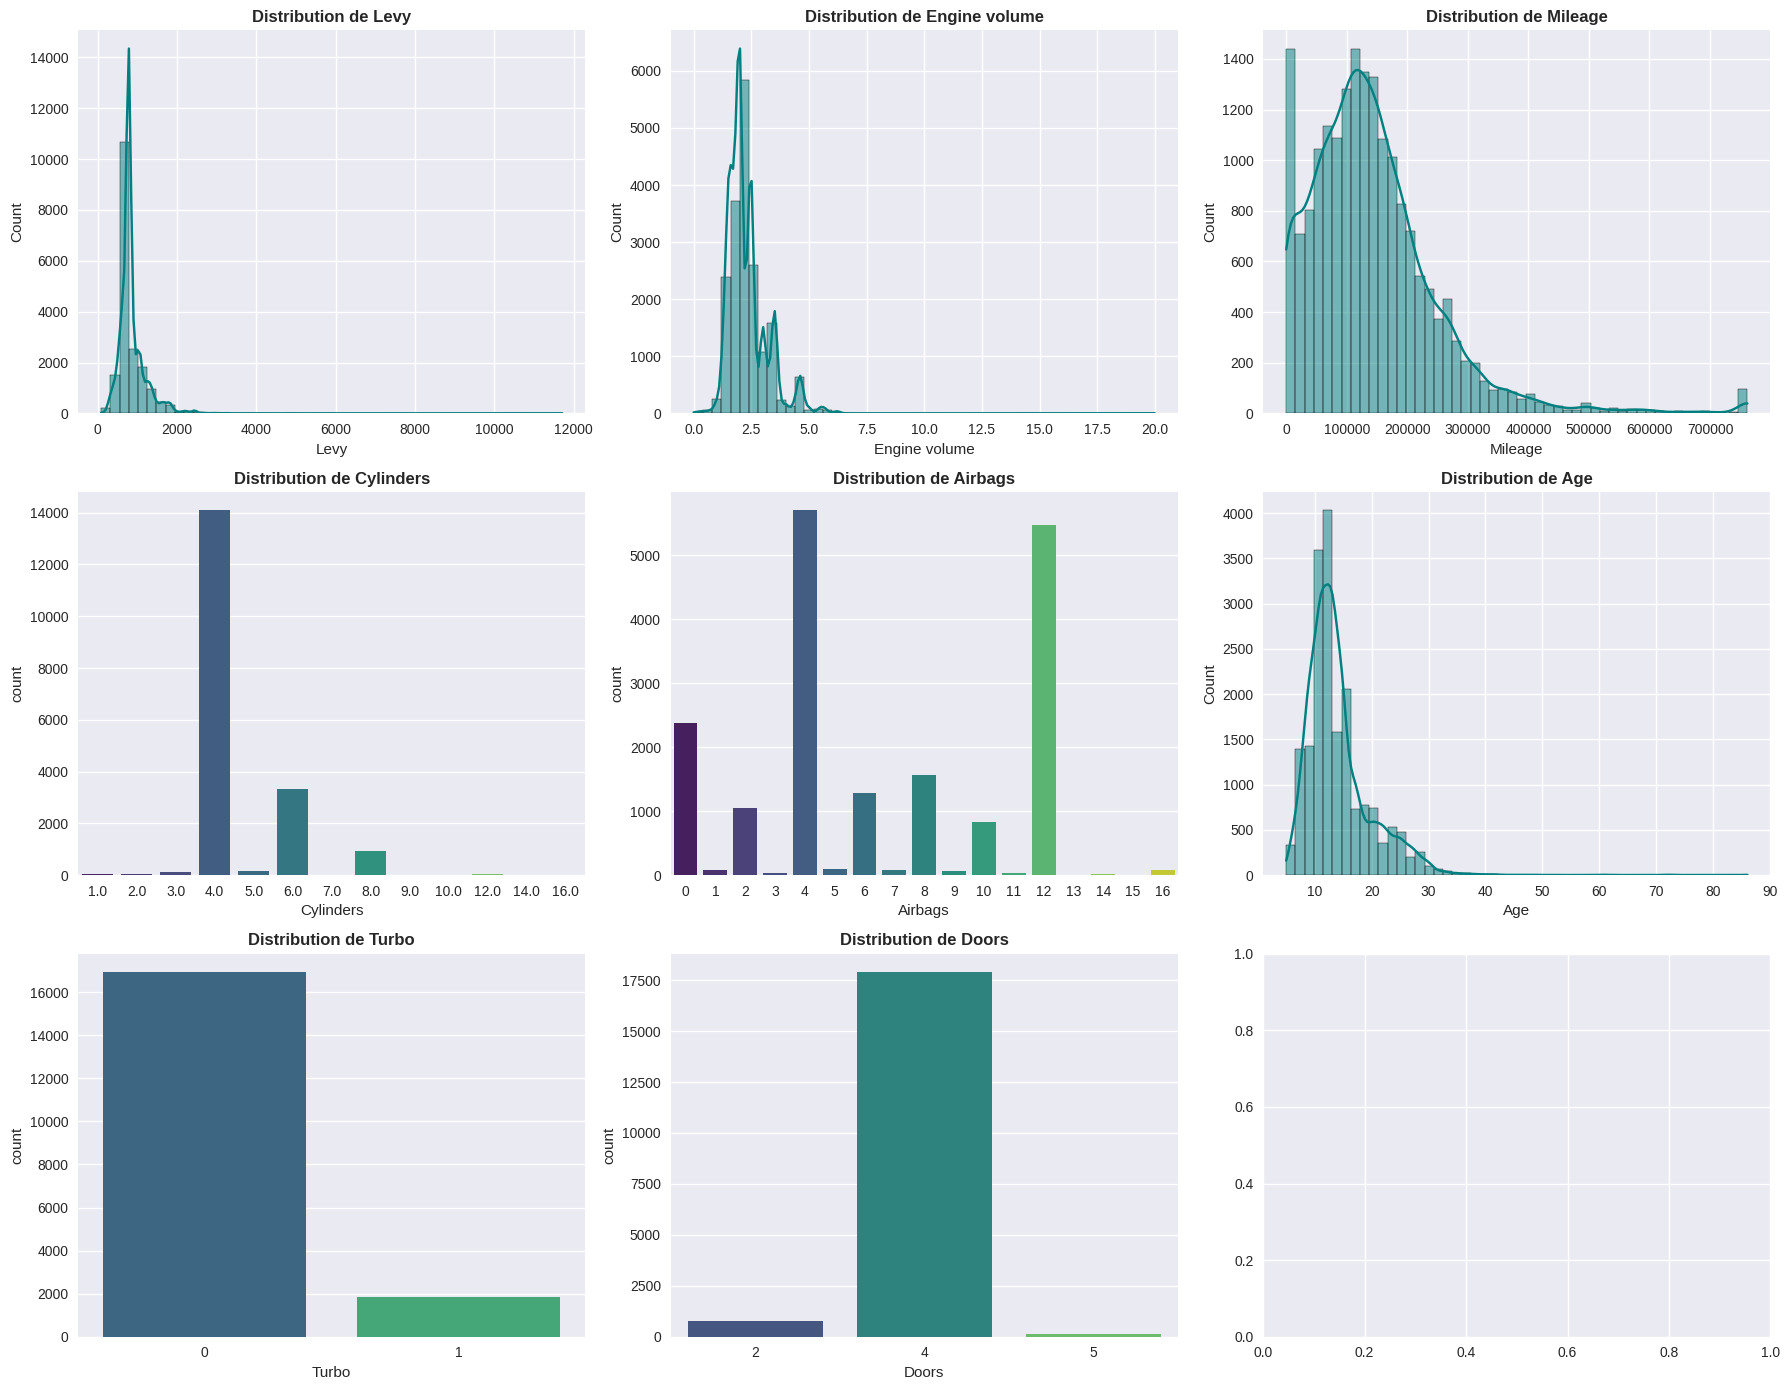

In [ ]:
# 1. ANALYSE UNIVARIÉE

print("\n1. Analyse univariée\n")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Prix original
axes[0,0].hist(df_eda['Price'], bins=100, color='skyblue', edgecolor='black')
axes[0,0].set_title('Distribution du Prix (échelle originale)', fontweight='bold')
axes[0,0].set_xlabel('Prix ($)')
axes[0,0].set_ylabel('Fréquence')

# log_price
axes[0,1].hist(df_eda['log_price'], bins=80, color='lightcoral', edgecolor='black')
axes[0,1].set_title('Distribution log(Price) – transformation réussie', fontweight='bold')
axes[0,1].set_xlabel('log(Price)')

# Boxplots
sns.boxplot(y=df_eda['Price'], ax=axes[1,0], color='salmon')
axes[1,0].set_title('Boxplot Prix (après nettoyage)')

sns.boxplot(y=df_eda['log_price'], ax=axes[1,1], color='lightgreen')
axes[1,1].set_title('Boxplot log(Price)')

plt.tight_layout()
plt.show()

# Distribution des variables numériques clés
num_vars = ['Levy', 'Engine volume', 'Mileage', 'Cylinders', 'Airbags', 'Age', 'Turbo', 'Doors']
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.ravel()
for i, col in enumerate(num_vars):
    if df_eda[col].nunique() <= 20:
        sns.countplot(x=col, data=df_eda, ax=axes[i], palette='viridis')
    else:
        sns.histplot(df_eda[col], kde=True, ax=axes[i], color='teal', bins=50)
    axes[i].set_title(f'Distribution de {col}', fontweight='bold')
plt.tight_layout()
plt.show()



2. Analyse bivariée



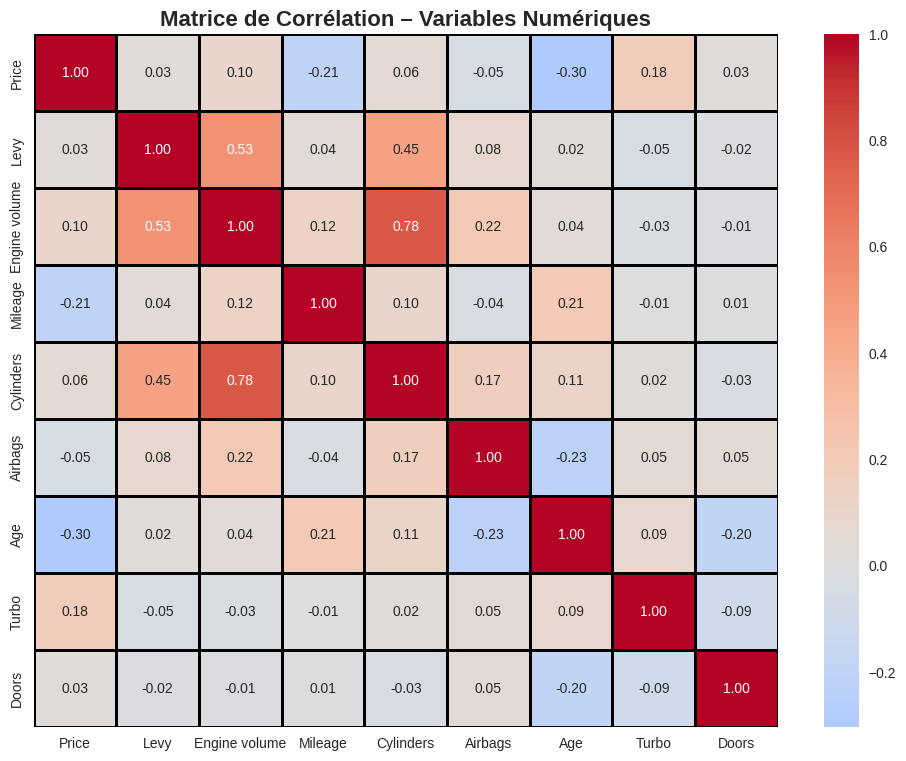

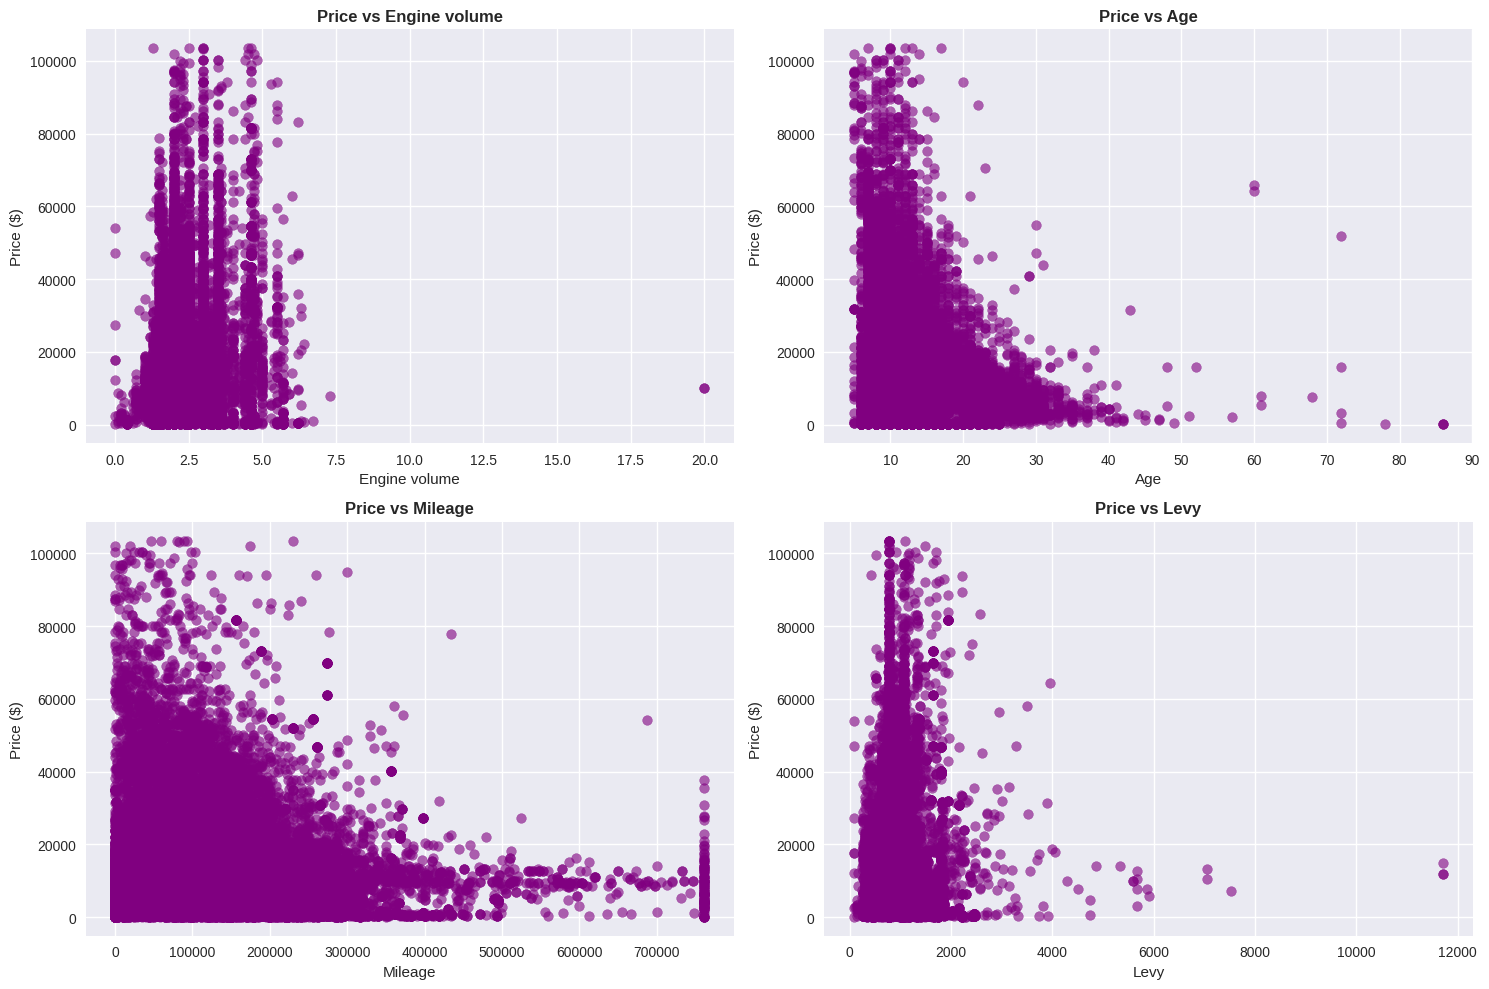

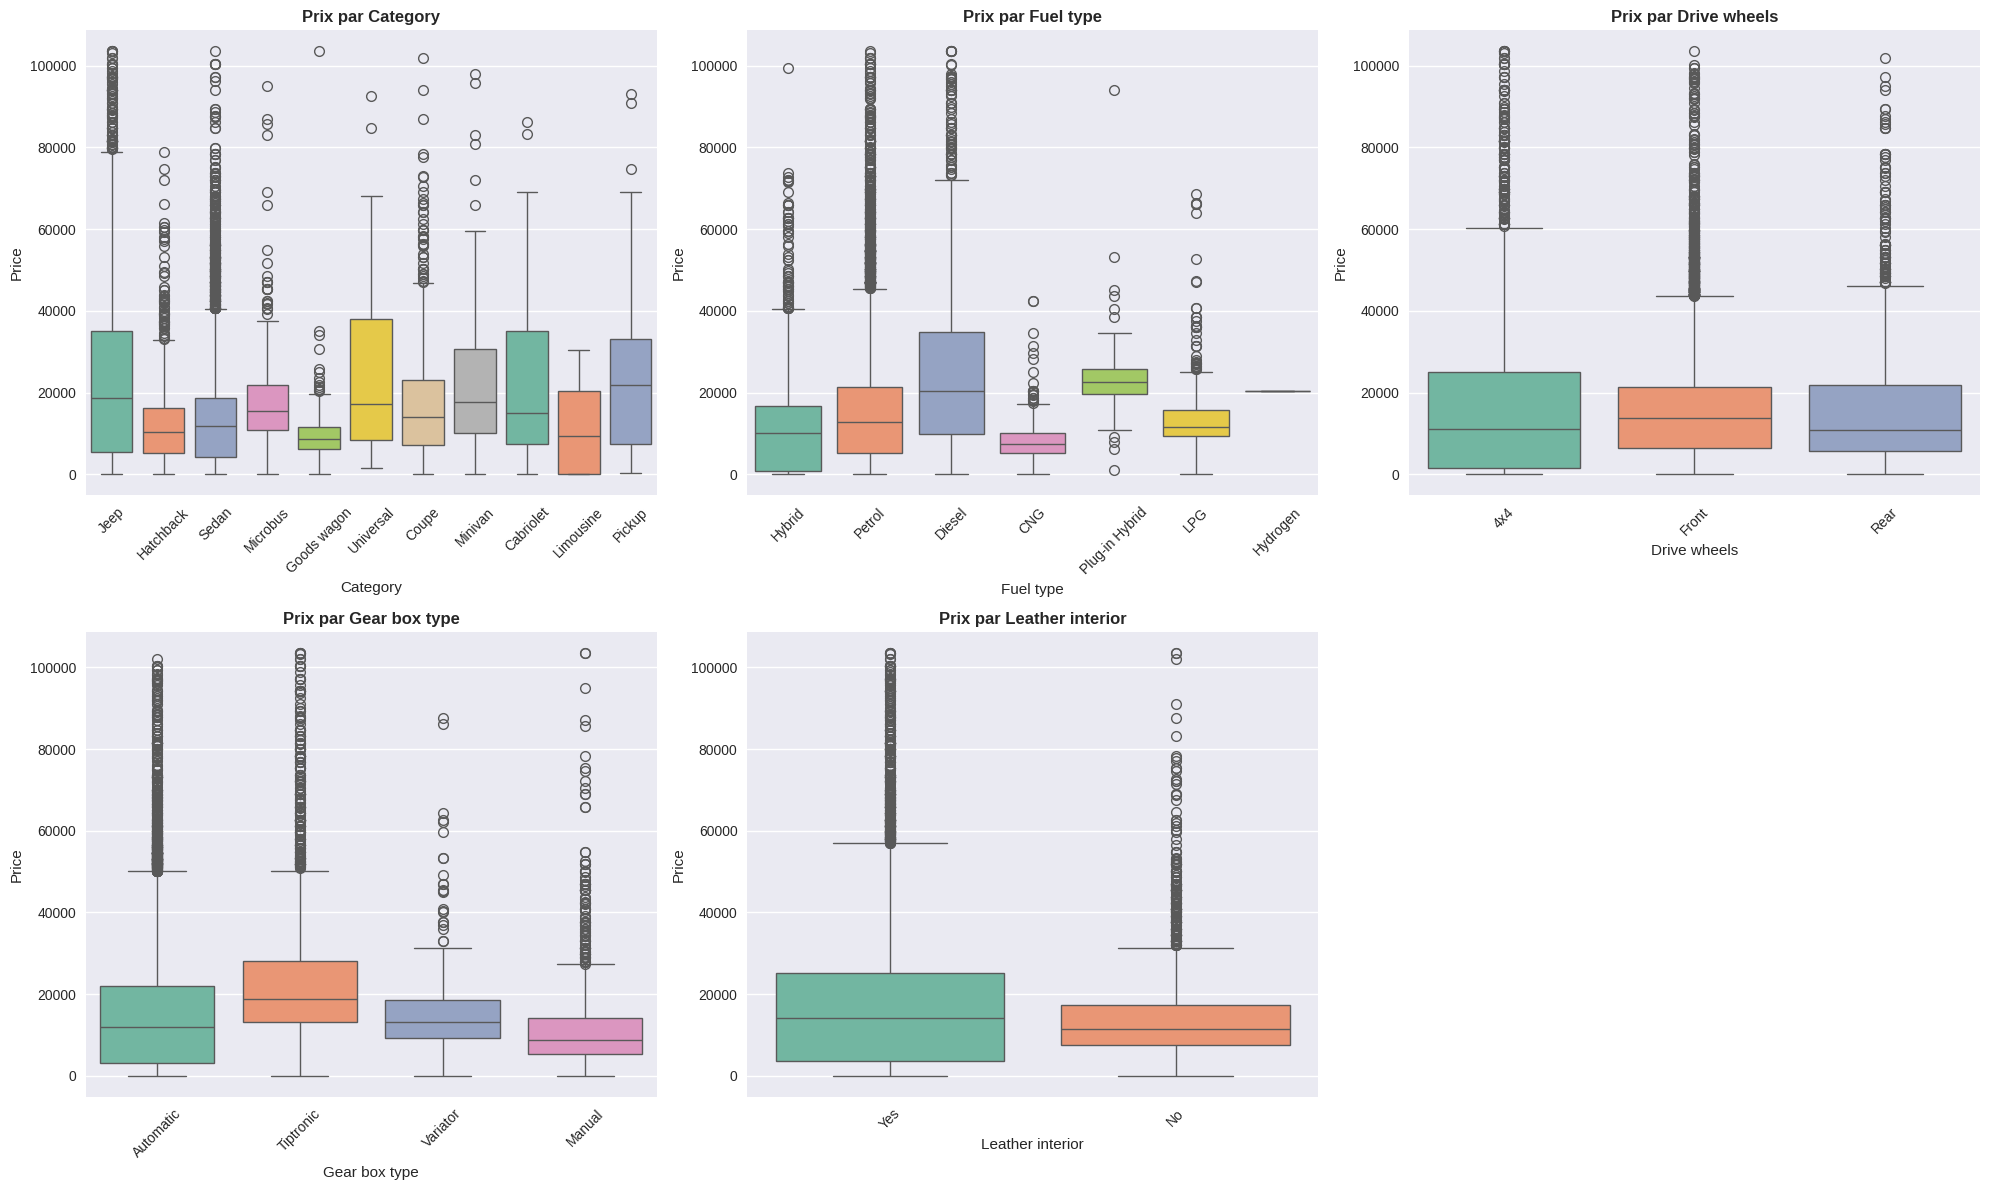

In [ ]:

# 2. ANALYSE BIVARIÉE

print("\n2. Analyse bivariée\n")

# Matrice de corrélation (variables numériques)
corr_cols = ['Price', 'Levy', 'Engine volume', 'Mileage', 'Cylinders', 'Airbags', 'Age', 'Turbo', 'Doors']
corr = df_eda[corr_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', linewidths=1, linecolor='black')
plt.title('Matrice de Corrélation – Variables Numériques', fontweight='bold', size=16)
plt.show()

# Scatter plots clés
key_scatter = ['Engine volume', 'Age', 'Mileage', 'Levy']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()
for i, var in enumerate(key_scatter):
    axes[i].scatter(df_eda[var], df_eda['Price'], alpha=0.6, color='purple')
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Price ($)')
    axes[i].set_title(f'Price vs {var}', fontweight='bold')
plt.tight_layout()
plt.show()

# Boxplots avec variables catégorielles originales (on les récupère du df brut)
cat_box = ['Category', 'Fuel type', 'Drive wheels', 'Gear box type', 'Leather interior']
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.ravel()
for i, col in enumerate(cat_box):
    sns.boxplot(x=col, y='Price', data=df_original, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Prix par {col}', fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45)
axes[-1].axis('off')  # on cache le dernier subplot vide
plt.tight_layout()
plt.show()



3. Analyse multivariée



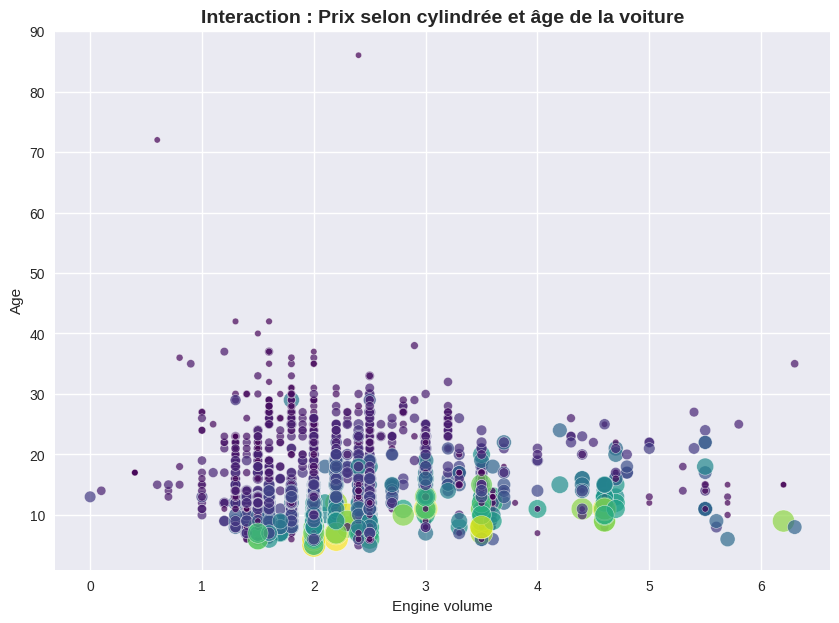


Détection de colinéarité (VIF) – variables numériques :


,Variable,VIF
3,Cylinders,39.31
1,Engine volume,23.66
7,Doors,17.91
0,Levy,8.31
5,Age,7.48
4,Airbags,3.68
2,Mileage,2.90
6,Turbo,1.13


In [ ]:

# 3. ANALYSE MULTIVARIÉE

print("\n3. Analyse multivariée\n")

# Interaction Engine volume × Age
plt.figure(figsize=(10, 7))
sns.scatterplot(x='Engine volume', y='Age', size='Price', hue='Price',
                data=df_eda.sample(3000, random_state=42), palette='viridis',
                sizes=(20, 300), alpha=0.7, legend=False)
plt.title('Interaction : Prix selon cylindrée et âge de la voiture', fontweight='bold', size=14)
plt.show()

# VIF – Détection de colinéarité
print("\nDétection de colinéarité (VIF) – variables numériques :")
vif_df = df_eda[['Levy', 'Engine volume', 'Mileage', 'Cylinders', 'Airbags', 'Age', 'Turbo', 'Doors']]
vif = pd.DataFrame()
vif["Variable"] = vif_df.columns
vif["VIF"] = [variance_inflation_factor(vif_df.values, i) for i in range(vif_df.shape[1])]
vif = vif.sort_values("VIF", ascending=False)
display(vif.round(2))



- ÉTAPE 4 : PRÉPARATION DES DONNÉES POUR LA MODÉLISATION



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
import pandas as pd
import numpy as np

# 1. Séparation train-test : 80%-20% avec random_state=42

print("1. Séparation train-test (80% / 20%) – random_state=42")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=pd.qcut(y, q=10, duplicates='drop')
)

# On conserve aussi le prix original pour l'évaluation finale
y_price_train = y_price.loc[y_train.index]
y_price_test  = y_price.loc[y_test.index]

print(f"   → Train : {X_train.shape[0]:,} lignes ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"   → Test  : {X_test.shape[0]:,} lignes ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"   → Total features : {X_train.shape[1]} colonnes\n")

# 2. Normalisation/Standardisation

print("2. Normalisation/Standardisation")

# Colonnes numériques à standardiser
numeric_columns = ['Levy', 'Engine volume', 'Mileage', 'Cylinders',
                   'Airbags', 'Doors', 'Leather interior', 'Turbo', 'Age']

# Vérification qu'elles existent
numeric_columns = [col for col in numeric_columns if col in X_train.columns]
print(f"   → Variables numériques à standardiser ({len(numeric_columns)}) :")
print(f"     {numeric_columns}\n")


# Toutes les colonnes One-Hot restent intactes (passthrough)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_columns),                                   # Standardisation
        ('cat', 'passthrough', [col for col in X_train.columns if col not in numeric_columns])  # One-Hot préservées
    ],
    remainder='passthrough'
)

# Application du préprocesseur
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed  = preprocessor.transform(X_test)

print("   Préprocesseur appliqué avec succès !")
print(f"   → One-Hot Encoding préservé (0/1 intacts)")
print(f"   → X_train après traitement : {X_train_processed.shape}")
print(f"   → X_test  après traitement : {X_test_processed.shape}\n")

# 3. Création de DataFrames propres pour l'entraînement et le test

print("3. Création des DataFrames finaux")

# Ordre des colonnes après transformation
final_columns = numeric_columns + [col for col in X_train.columns if col not in numeric_columns]

X_train_df = pd.DataFrame(X_train_processed, columns=final_columns, index=X_train.index)
X_test_df  = pd.DataFrame(X_test_processed,  columns=final_columns, index=X_test.index)

print(f"   → X_train_df créé : {X_train_df.shape}")
print(f"   → X_test_df  créé : {X_test_df.shape}")
print(f"   → Prêt pour la modélisation !\n")



1. Séparation train-test (80% / 20%) – random_state=42
   → Train : 15,025 lignes (80.0%)
   → Test  : 3,757 lignes (20.0%)
   → Total features : 1670 colonnes

2. Normalisation/Standardisation
   → Variables numériques à standardiser (9) :
     ['Levy', 'Engine volume', 'Mileage', 'Cylinders', 'Airbags', 'Doors', 'Leather interior', 'Turbo', 'Age']

   Préprocesseur appliqué avec succès !
   → One-Hot Encoding préservé (0/1 intacts)
   → X_train après traitement : (15025, 1670)
   → X_test  après traitement : (3757, 1670)

3. Création des DataFrames finaux
   → X_train_df créé : (15025, 1670)
   → X_test_df  créé : (3757, 1670)
   → Prêt pour la modélisation !



- ÉTAPE 5 : MODÉLISATION & ÉVALUATION COMPLÈTE

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, RidgeCV


print("="*95)
print("ÉTAPE 5 : MODÉLISATION ET ÉVALUATION AVEC TOUTES LES TECHNIQUES DE VALIDATION")
print("="*95)

results = []  # Pour le tableau final

# Fonction d'évaluation propre (retour en échelle Prix $)
def evaluate(y_true, y_pred, name, std=None):
    r2  = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    print(f"   → {name}")
    print(f"     R² = {r2:.4f} | RMSE = {rmse:,.0f}$ | MAE = {mae:,.0f}$")
    if std:
        print(f"     ± std = {std:.4f}")
    results.append({'Méthode': name, 'R²': round(r2,4), 'RMSE': round(rmse), 'MAE': round(mae)})



ÉTAPE 5 : MODÉLISATION ET ÉVALUATION AVEC TOUTES LES TECHNIQUES DE VALIDATION



A. Régression Linéaire Simple (Engine volume)
   → A. Simple (Engine volume)
     R² = -0.2739 | RMSE = 18,034$ | MAE = 11,834$


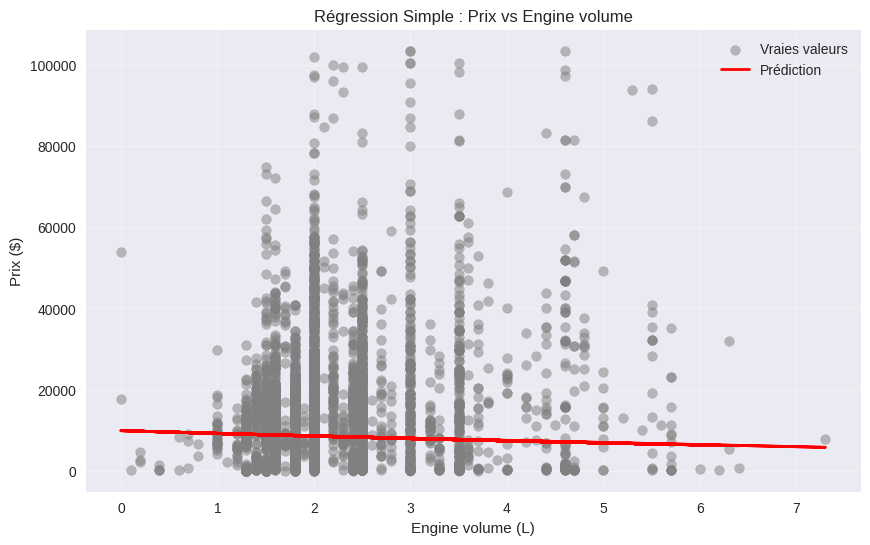

In [ ]:

# A. RÉGRESSION LINÉAIRE SIMPLE (Baseline) →

print("\nA. Régression Linéaire Simple (Engine volume)")

lr_simple = LinearRegression()
lr_simple.fit(X_train[['Engine volume']], y_train)
pred_simple = lr_simple.predict(X_test[['Engine volume']])

evaluate(np.expm1(y_test), np.expm1(pred_simple), "A. Simple (Engine volume)")

# Visualisation
plt.figure(figsize=(10,6))
plt.scatter(X_test['Engine volume'], np.expm1(y_test), alpha=0.5, label='Vraies valeurs', color='gray')
plt.plot(X_test['Engine volume'], np.expm1(pred_simple), color='red', linewidth=2, label='Prédiction')
plt.xlabel('Engine volume (L)')
plt.ylabel('Prix ($)')
plt.title('Régression Simple : Prix vs Engine volume')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:

# B. RÉGRESSION LINÉAIRE MULTIPLE

print("\nB. Régression Linéaire Multiple (toutes les features)")

lr_full = LinearRegression()
lr_full.fit(X_train_df, y_train)

pred_train_full = lr_full.predict(X_train_df)
pred_test_full  = lr_full.predict(X_test_df)

print("   → Score Train :")
evaluate(np.expm1(y_train), np.expm1(pred_train_full), "Train (Multiple)")
print("   → Score Test :")
evaluate(np.expm1(y_test),  np.expm1(pred_test_full),  "B. Multiple (Split 80/20)")

# Top 10 features les plus importantes
coefs = pd.DataFrame({
    'Feature': X_train_df.columns,
    'Coefficient': lr_full.coef_
})
coefs['Abs_Coef'] = np.abs(coefs['Coefficient'])
top10 = coefs.sort_values('Abs_Coef', ascending=False).head(10)

print("\nTOP 10 VARIABLES LES PLUS INFLUENTES (coef absolu) :")
display(top10[['Feature', 'Coefficient']].round(6))



B. Régression Linéaire Multiple (toutes les features)
   → Score Train :
   → Train (Multiple)
     R² = 0.2839 | RMSE = 13,219$ | MAE = 7,963$
   → Score Test :
   → B. Multiple (Split 80/20)
     R² = 0.0871 | RMSE = 15,266$ | MAE = 9,143$

TOP 10 VARIABLES LES PLUS INFLUENTES (coef absolu) :


,Feature,Coefficient
1426,Model_Sprinter სატვირთო,-6.185510
573,Model_Corolla 140,-5.814053
1425,Model_Sprinter VIP CLASS,-5.725271
1070,Model_Mark X Zio,-5.260727
683,Model_E 55,-5.089564
1305,Model_Regal,-5.071793
1348,Model_Sai,-4.977022
1441,Model_TL saber,-4.912802
879,Model_Golf GTI,-4.341113
479,Model_CRX,-4.215557


In [ ]:
# C. VALIDATION CROISÉE K-FOLD (K=3,5,10)

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, LeaveOneOut, cross_val_score

print("\nC. K-Fold Cross Validation")

pipeline_kfold = Pipeline([
    ('prep', preprocessor),
    ('lr', LinearRegression())
])

for k in [3, 5, 10]:
    start = time.time()
    cv = KFold(n_splits=k, shuffle=True, random_state=42)
    r2_scores = cross_val_score(pipeline_kfold, X, y, cv=cv, scoring='r2')
    duration = time.time() - start
    print(f"   K={k} → R² = {r2_scores.mean():.4f} ± {r2_scores.std():.4f} (temps: {duration:.1f}s)")
    results.append({'Méthode': f'K-Fold (K={k})', 'R²': round(r2_scores.mean(),4)})


C. K-Fold Cross Validation
   K=3 → R² = 0.2780 ± 0.0074 (temps: 27.4s)
   K=5 → R² = 0.2842 ± 0.0112 (temps: 47.7s)
   K=10 → R² = 0.2862 ± 0.0216 (temps: 103.5s)


In [ ]:
# D. Stratified K-Fold (K=5) – version corrigée

from sklearn.model_selection import StratifiedKFold

print("\nD. Stratified K-Fold (K=5) – avec stratification sur prix discrétisé")

y_strat = pd.qcut(y, q=5, labels=False, duplicates='drop')
print(f"   → Distribution des 5 classes :\n{y_strat.value_counts().sort_index()}")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
r2_scores_strat = []

for train_idx, test_idx in skf.split(X, y_strat):  # Stratifie sur y_strat
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    pipeline_kfold.fit(X_tr, y_tr)
    pred = pipeline_kfold.predict(X_te)
    r2_scores_strat.append(r2_score(np.expm1(y_te), np.expm1(pred)))

r2_mean_strat = np.mean(r2_scores_strat)
r2_std_strat  = np.std(r2_scores_strat)
print(f"   → Stratified K-Fold → R² = {r2_mean_strat:.4f} ± {r2_std_strat:.4f}")
results.append({'Méthode': 'Stratified K-Fold', 'R²': round(r2_mean_strat,4)})


D. Stratified K-Fold (K=5) – avec stratification sur prix discrétisé
   → Distribution des 5 classes :
log_price
0    3792
1    3799
2    3794
3    3660
4    3737
Name: count, dtype: int64
   → Stratified K-Fold → R² = 0.0690 ± 0.0610


In [ ]:

# F. LOOCV (sur 500 observations pour rester raisonnable)

print("\nF. Leave-One-Out CV (échantillon de 500)")

small_X = X.sample(500, random_state=42)
small_y = y.loc[small_X.index]
loocv = LeaveOneOut()
r2_loocv = cross_val_score(pipeline_kfold, small_X, small_y, cv=loocv, scoring='r2')
print(f"   LOOCV → R² moyen = {r2_loocv.mean():.4f} ± {r2_loocv.std():.4f}")
results.append({'Méthode': 'LOOCV (500 obs)', 'R²': round(r2_loocv.mean(),4)})



F. Leave-One-Out CV (échantillon de 500)
   LOOCV → R² moyen = nan ± nan


In [ ]:

# G. NESTED CROSS VALIDATION (5x5) – Évaluation la plus robuste

print("\nG. Nested Cross Validation (5x5) – Évaluation finale non biaisée")

from sklearn.model_selection import cross_val_score
outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)
nested_scores = []

for train_idx, test_idx in outer_cv.split(X):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    pipeline_kfold.fit(X_tr, y_tr)
    pred_nested = pipeline_kfold.predict(X_te)
    nested_scores.append(r2_score(np.expm1(y_te), np.expm1(pred_nested)))

nested_mean = np.mean(nested_scores)
nested_std  = np.std(nested_scores)
print(f"   Nested CV (5x5) → R² = {nested_mean:.4f} ± {nested_std:.4f}")
results.append({'Méthode': 'Nested CV 5x5 (plus robuste)', 'R²': round(nested_mean,4)})





G. Nested Cross Validation (5x5) – Évaluation finale non biaisée
   Nested CV (5x5) → R² = 0.0783 ± 0.0743


In [ ]:
# TABLEAU COMPARATIF FINAL

print("\n" + "="*95)
print("TABLEAU COMPARATIF FINAL DE TOUTES LES MÉTHODES")
print("="*95)
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('R²', ascending=False).reset_index(drop=True)
display(results_df.style.background_gradient(cmap='Greens'))



TABLEAU COMPARATIF FINAL DE TOUTES LES MÉTHODES


,Méthode,R²,RMSE,MAE
0,K-Fold (K=10),0.286200,nan,nan
1,K-Fold (K=5),0.284200,nan,nan
2,Train (Multiple),0.283900,13219.000000,7963.000000
3,K-Fold (K=3),0.278000,nan,nan
4,B. Multiple (Split 80/20),0.087100,15266.000000,9143.000000
5,Nested CV 5x5 (plus robuste),0.078300,nan,nan
6,Stratified K-Fold,0.069000,nan,nan
7,A. Simple (Engine volume),-0.273900,18034.000000,11834.000000
8,LOOCV (500 obs),nan,nan,nan


In [ ]:

# Améliorations avec Modèles Non Linéaires

print("\n : Test avec Random Forest pour comparaison")

from sklearn.ensemble import RandomForestRegressor

# Pipeline avec RF (pas de scaling needed pour trees, mais on garde pour cohérence)
pipeline_rf = Pipeline([
    ('prep', preprocessor),  # Ton preprocessor existant
    ('rf', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))
])

# Fit sur train
pipeline_rf.fit(X_train, y_train)

# Prédictions et metrics sur test (back-transform)
pred_rf = pipeline_rf.predict(X_test)
r2_rf = r2_score(np.expm1(y_test), np.expm1(pred_rf))
rmse_rf = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(pred_rf)))
mae_rf = mean_absolute_error(np.expm1(y_test), np.expm1(pred_rf))

print(f"Random Forest sur Test: R² = {r2_rf:.4f}, RMSE = {rmse_rf:.0f}, MAE = {mae_rf:.0f}")

# Ajoute à ton tableau results
results.append({'Méthode': 'Bonus: Random Forest', 'R²': round(r2_rf,4), 'RMSE': round(rmse_rf), 'MAE': round(mae_rf)})

# Re-affiche le tableau mis à jour
results_df = pd.DataFrame(results).sort_values('R²', ascending=False).reset_index(drop=True)
display(results_df.style.background_gradient(cmap='Greens'))


 : Test avec Random Forest pour comparaison
Random Forest sur Test: R² = 0.6977, RMSE = 8784, MAE = 4368


,Méthode,R²,RMSE,MAE
0,Bonus: Random Forest,0.697700,8784.000000,4368.000000
1,K-Fold (K=10),0.286200,nan,nan
2,K-Fold (K=5),0.284200,nan,nan
3,Train (Multiple),0.283900,13219.000000,7963.000000
4,K-Fold (K=3),0.278000,nan,nan
5,B. Multiple (Split 80/20),0.087100,15266.000000,9143.000000
6,Nested CV 5x5 (plus robuste),0.078300,nan,nan
7,Stratified K-Fold,0.069000,nan,nan
8,A. Simple (Engine volume),-0.273900,18034.000000,11834.000000
9,LOOCV (500 obs),nan,nan,nan
